# Gradient Descent: Full Datasets, Single Examples, and Mini-batches

## 1. Introduction and learning objectives

An objective describes which parameters are desirable; an optimizer describes how to search for them. A direct least-squares formula is convenient for a small linear problem, but many later models have no comparable closed form. Gradient descent repeatedly uses local slope information to improve a parameter vector.

You will derive its update rule, examine exactly when a step decreases a simple quadratic, distinguish batch, stochastic, and mini-batch gradients, and compare them with fair computational budgets. You will implement all three variants yourself and investigate feature scaling, random order, monitoring, and stopping.

Recommended prerequisite: [Linear Regression](linear-regression.ipynb). This notebook restates the required notation and calculus, so you can work independently if you already understand derivatives, vector dot products, and squared error. No optimizer is supplied in executable code.

Try each exercise in its dedicated answer cell first. A collapsed **Show hint** and a separate **Show worked solution — try the exercise first** follow immediately below it. Reference Python is displayed text and is not executed by Run All; some snippets name earlier references in this chapter.

### Working environment

Run this setup cell before working on the implementation challenges. It imports numerical and plotting tools, without defining any exercise solution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 2.01 — Separate a model from an optimizer

**Type:** Conceptual · **Answer:** Markdown

Two people minimize the same linear-regression loss. One solves an equation; the other repeatedly changes parameters. Identify what is shared and what differs. Explain why switching optimizers alone does not make the prediction function nonlinear.

**Expected outcome:** A distinction between the model family, objective, and search procedure.

**Your response to Exercise 2.01**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.01**

Compare the prediction formula and loss before comparing the steps used to fit parameters.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.01**

Both people can share the same model $\hat y=Xw+b\mathbf1$ and the same least-squares objective. They differ in the numerical procedure used to choose parameters: solving stationary equations versus making successive updates.

An optimizer searches within the chosen model family. Replacing it does not introduce nonlinear features or change the prediction formula. Under suitable conditions both procedures can reach the same training predictions, though finite iterative budgets and numerical conditioning affect the observed fit.

</details>

## 2. Prerequisites and mathematical foundations

### A gradient is local information

Write all $p$ adjustable parameters as $\theta\in\mathbb R^p$. In linear regression, $\theta=(b,w_1,\ldots,w_d)^T$ and $p=d+1$. The function $J(\theta)$ is a scalar objective. Its gradient $g=\nabla_\theta J$ is the vector of partial derivatives, each changing one parameter while the others stay fixed.

For a sufficiently small change vector $\Delta$, differentiability gives a first-order approximation

$$
J(\theta+\Delta)\approx J(\theta)+g^T\Delta.
$$

The Euclidean length of a vector $v$ is $\lVert v\rVert_2=\sqrt{\sum_jv_j^2}$. The product $g^T\Delta=\sum_j g_j\Delta_j$ is a dot product. It estimates the change in the objective rather than its new absolute value. If $\Delta=-\alpha g$ with scalar step size $\alpha>0$, the predicted change is $-\alpha g^Tg=-\alpha\lVert g\rVert_2^2$, which is negative whenever $g\ne0$.

This motivates gradient descent, not an unlimited-step guarantee. The approximation neglects curvature. A large step can pass through a low-loss region and finish at a higher loss. The negative gradient is the direction of steepest local decrease under a Euclidean length constraint; changing feature units changes the geometry of this statement.

### Exercise 2.02 — Use a local approximation

**Type:** Numerical · **Answer:** Markdown

At a parameter vector with $J=7$ and gradient $g=(2,-1)^T$, consider $\Delta=(-0.1,0.05)^T$. Calculate the predicted objective change and approximate new value. Explain why the approximation is not an exact evaluation.

**Expected outcome:** A dot-product calculation and a statement of the small-change assumption.

**Your response to Exercise 2.02**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.02**

The first-order estimate uses a dot product, not the lengths of the two vectors.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.02**

$g^T\Delta=2(-0.1)+(-1)(0.05)=-0.25$, so the approximate new value is $7-0.25=6.75$.

This is a local approximation at the original parameter vector. It omits curvature and higher-order effects. Without evaluating the actual function or bounding those effects, it does not establish an exact new value.

</details>

### Objective averages and a linear-regression reminder

For $n$ observations define individual losses $\ell_i(\theta)$ and their average

$$
J(\theta)=\frac1n\sum_{i=1}^n\ell_i(\theta),
\qquad
\nabla J(\theta)=\frac1n\sum_{i=1}^n\nabla\ell_i(\theta).
$$

The index $i$ identifies an observation. Differentiating an average gives the average of derivatives because differentiation is linear.

For linear regression let $X\in\mathbb R^{n\times d}$ contain row-wise examples, $y\in\mathbb R^n$ the targets, $w\in\mathbb R^d$ the weights, and $b$ the intercept. Predictions are $Xw+b\mathbf1_n$, where $\mathbf1_n$ is a vector of ones. Each residual is $r_i=X_{i:}w+b-y_i$; the colon means take the whole row. With $\ell_i=\frac12r_i^2$, the chain rule gives

$$
\nabla_w J=\frac1nX^Tr,\qquad
\frac{\partial J}{\partial b}=\frac1n\sum_i r_i.
$$

Here $T$ denotes transpose, $\nabla_w$ collects weight derivatives, and $\partial/\partial b$ is the intercept derivative. The factor $1/2$ in the loss cancels the square's derivative factor of two. Keep target arrays at shape `(n,)` in this notebook.

## 3. Theoretical development and worked examples

### Batch gradient descent

Let $\theta^{(t)}$ be the parameters after $t$ updates; the parenthesized superscript is a time index, not a power. Batch gradient descent evaluates every example at the same current parameters:

$$
g^{(t)}=\nabla J(\theta^{(t)}),\qquad
\theta^{(t+1)}=\theta^{(t)}-\alpha_t g^{(t)}.
$$

The positive scalar $\alpha_t$ is the learning rate at update $t$. With a constant rate, write $\alpha_t=\alpha$. Compute every gradient component before changing any parameter. Updating one weight and then computing another gradient at that new weight produces a different procedure.

**Worked example.** For scalar $\theta$, let $J(\theta)=\frac12(\theta-2)^2$. Its derivative is $\theta-2$. Starting at zero with $\alpha=0.3$, the first gradient is $-2$, so the first new parameter is $0-0.3(-2)=0.6$. The next gradient is $-1.4$, giving $0.6-0.3(-1.4)=1.02$. The gradient magnitude shrinks as the parameter approaches two.

### Exercise 2.03 — Perform two updates by hand

**Type:** Numerical · **Answer:** Markdown

For $J(\theta)=\frac12(\theta+1)^2$, start at $\theta^{(0)}=2$ and use $\alpha=1/4$. Calculate two gradients, two updated parameters, and the loss after each update.

**Expected outcome:** A table indexed by update number, with each gradient evaluated before its corresponding update.

**Your response to Exercise 2.03**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.03**

Recompute the derivative after the first update rather than reusing the initial slope.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.03**

$J'(\theta)=\theta+1$. The calculations are:

| State | Parameter | Gradient at that state | Loss |
| --- | ---: | ---: | ---: |
| Initial | $2$ | $3$ | $9/2$ |
| After update 1 | $2-\frac14(3)=5/4$ | $9/4$ | $81/32$ |
| After update 2 | $5/4-\frac14(9/4)=11/16$ | $27/16$ | $729/512$ |

Both steps approach the minimizer $-1$, and their magnitudes decrease because the local derivative changes.

</details>

### Curvature explains overshooting

Consider the scalar quadratic $J(\theta)=\frac c2(\theta-a)^2$, with curvature $c>0$ and minimizer $a$. The gradient is $c(\theta-a)$. Define the parameter error $e_t=\theta^{(t)}-a$. Subtracting $a$ from the update gives

$$
e_{t+1}=(1-\alpha c)e_t.
$$

Repeated multiplication shrinks a nonzero error exactly when $|1-\alpha c|<1$. Rearranging the two inequalities $-1<1-\alpha c<1$ yields $0<\alpha<2/c$. When $0<\alpha c<1$, the approach does not change sides. When $1<\alpha c<2$, errors alternate signs while shrinking. At $\alpha c=2$, a nonzero error alternates without shrinking; above two it grows. If the initial error is zero, it stays zero regardless of these distinctions.

For a multivariable quadratic, the **Hessian** $H$ is the matrix of second partial derivatives. Along a direction $v$ satisfying $Hv=\lambda v$, the nonnegative number $\lambda$ is that direction's curvature; such a $v$ is called an eigenvector and $\lambda$ an eigenvalue. A symmetric quadratic can be decomposed into these directions. The steepest-curvature direction sets the restriction $0<\alpha<2/\lambda_{\max}$, where $\lambda_{\max}$ is the largest positive eigenvalue.

For linear-regression half-MSE, $H=\widetilde X^T\widetilde X/n$, using the intercept-augmented matrix $\widetilde X=[\mathbf1_n\;X]$. Zero-curvature directions reflect unidentifiable parameters; their components need not approach a unique value. These quadratic statements do not promise that a general neural network has a unique optimum or that a large gradient step is safe.

### Exercise 2.04 — Explain three step-size regimes

**Type:** Mathematical · **Answer:** Markdown

For $c=4$, derive the range of constant learning rates that shrink nonzero error. Choose one learning rate for monotone approach, one for decaying oscillation, and one for divergence. Justify each choice using the error multiplier.

**Expected outcome:** Inequalities and three explained examples, rather than a rule that all smaller rates are equally efficient.

**Your response to Exercise 2.04**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.04**

Study the error multiplier before choosing rates, and check the two boundary values separately.

Work with the absolute value of the error multiplier, then inspect its sign.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.04**

For $c=4$, shrinking nonzero error requires $|1-4\alpha|<1$. Rearrangement gives $0<\alpha<1/2$.

- $\alpha=0.1$ gives multiplier $0.6$: the error shrinks without changing sign.
- $\alpha=0.3$ gives multiplier $-0.2$: it changes sign while shrinking.
- $\alpha=0.6$ gives multiplier $-1.4$: its magnitude grows.

At $\alpha=1/2$, the multiplier is $-1$ and a nonzero error does not shrink. At $\alpha=1/4$ the multiplier is zero, reaching this scalar quadratic's minimum in one step.

</details>

### Stochastic gradient descent

Stochastic gradient descent, abbreviated SGD, samples one index $I_t$ and uses

$$
g^{(t)}=\nabla\ell_{I_t}(\theta^{(t)}).
$$

For a uniformly drawn index and parameters held fixed during sampling, the expectation, meaning the probability-weighted average over possible draws, is

$$
\mathbb E[g^{(t)}\mid\theta^{(t)}]
=\frac1n\sum_i\nabla\ell_i(\theta^{(t)})
=\nabla J(\theta^{(t)}).
$$

This **unbiasedness** concerns the gradient estimate at a fixed point. It does not say every update decreases full-data loss. A sampled observation can favor a direction that hurts others.

**Worked comparison.** Let $J(\theta)=\frac14[(\theta-1)^2+(\theta-3)^2]$. At $\theta=0$, the two individual gradients are $-1$ and $-3$, with mean $-2$. One batch update with $\alpha=0.1$ reaches $0.2$. If SGD processes the first observation then the second, it first reaches $0.1$, then uses the changed-point gradient $0.1-3=-2.9$ to reach $0.39$. Both procedures used two individual gradient evaluations, but one made one update and the other two. Averaging stale gradients is not the same as sequential updates.

### Mini-batches and epochs

A mini-batch $B_t$ is a subset or sampled collection of indices, with size $m_t=|B_t|$. Vertical bars here count its members. The update uses

$$
g^{(t)}=\frac1{m_t}\sum_{i\in B_t}\nabla\ell_i(\theta^{(t)}).
$$

Batch gradient descent uses $m_t=n$ and each example once in the estimate. SGD uses $m_t=1$. Mini-batches balance computation throughput and sampling noise. Divide by the actual batch size, including a final short batch; dividing by a preset larger size underweights that final group.

For independent uniform draws **with replacement** at a fixed $\theta$, an average of $m$ individual gradients is unbiased and its component-wise sampling variance is $1/m$ of the single-draw variance. Variance means the expected squared deviation from the mean. Sampling without replacement introduces dependence between draws and changes this variance formula.

An **epoch** is one complete pass through the training set. A common implementation shuffles the indices once per epoch and slices them into disjoint batches. This is random reshuffling, not independent sampling with replacement. At a fixed parameter vector, a random subset has an unbiased average; during an adaptive epoch, conditioning on earlier batches and updates can remove that simple guarantee for the remaining batch. Use the expectation argument only under its stated sampling conditions.

### Exercise 2.05 — Count work fairly

**Type:** Conceptual · **Answer:** Markdown

With $n=23$ observations, compare batch size 23, batch size 1, and batch size 5 over one shuffled epoch. State the number of updates, number of examples processed, and size of any last batch.

**Expected outcome:** A comparison that distinguishes update count from data passes and explains how to average the last batch.

**Your response to Exercise 2.05**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.05**

The number of updates is the ceiling of n divided by the batch size.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.05**

| Batch size | Updates per epoch | Examples processed | Final batch |
| ---: | ---: | ---: | ---: |
| 23 | 1 | 23 | 23 |
| 1 | 23 | 23 | 1 |
| 5 | 5 | 23 | 3 |

For batch size five, the sizes are $5,5,5,5,3$. Average the last gradient by three, not five. Equal epoch counts control examples processed here, while update counts differ substantially.

</details>

### Exercise 2.06 — Show why a sampled mean can be unbiased

**Type:** Mathematical · **Answer:** Markdown

For fixed $\theta$, define $g_i=\nabla\ell_i(\theta)$. Let $I_1,\ldots,I_m$ be independent uniform draws from $\{1,\ldots,n\}$. Derive the expectation of $\frac1m\sum_{k=1}^m g_{I_k}$ using linearity of expectation. Explain what is held fixed.

**Expected outcome:** A short derivation with the sampling assumptions stated explicitly.

**Your response to Exercise 2.06**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.06**

First take the expectation of one uniformly selected gradient, with the parameters held fixed.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.06**

For each draw, $\mathbb E[g_{I_k}]=\sum_{i=1}^n(1/n)g_i$. Thus
$$
\mathbb E\left[\frac1m\sum_{k=1}^m g_{I_k}\right]
=\frac1m\sum_{k=1}^m\frac1n\sum_{i=1}^n g_i
=\frac1n\sum_{i=1}^n g_i=\nabla J(\theta).
$$
The dataset and parameter vector stay fixed during this calculation. Linearity of expectation itself does not require independent draws if each marginal distribution is uniform; independence is needed for the simple $1/m$ variance calculation. Adaptive within-epoch updates require the more careful conditioning discussed in the text.

</details>

## 4. Guided exercises

### Exercise 2.07 — Compare sequential and averaged gradients

**Type:** Numerical · **Answer:** Markdown

For individual losses $\ell_1(\theta)=\frac12(\theta+2)^2$ and $\ell_2(\theta)=\frac12(\theta-4)^2$, start at $\theta=1$ and use $\alpha=0.2$. Compare one full-batch update with two SGD updates in each possible order.

**Expected outcome:** Three final parameters, plus a written explanation of order dependence. This exercise counts the same number of individual gradient evaluations.

**Your response to Exercise 2.07**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.07**

For SGD, the second observation sees the parameter produced by the first observation.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.07**

At $\theta=1$, the individual derivatives are $3$ and $-3$. Their average is zero, so the full-batch update remains at $1$.

For order 1 then 2: first $\theta=1-0.2(3)=0.4$; then $\theta=0.4-0.2(0.4-4)=1.12$.

For order 2 then 1: first $\theta=1-0.2(-3)=1.6$; then $\theta=1.6-0.2(1.6+2)=0.88$.

The different final values arise because sequential gradients are evaluated at different parameter states. All three comparisons used two individual gradient evaluations.

</details>

### Scaling, monitoring, and stopping

Different feature units can create a long, narrow loss surface. A rate small enough for its steep direction can be frustratingly slow along a flat direction. Standardizing feature $j$ uses training mean $\mu_j$ and training standard deviation $s_j$:

$$
\mu_j=\frac1n\sum_iX_{ij},\qquad
s_j=\sqrt{\frac1n\sum_i(X_{ij}-\mu_j)^2},\qquad
X'_{ij}=(X_{ij}-\mu_j)/s_j.
$$

The prime marks transformed features. If $s_j=0$, do not divide by zero: remove the constant feature or use a documented scale of one. Apply the same training-derived transformation to validation and test observations. Computing new means on the test set changes the evaluation procedure and leaks information about that set.

To translate fitted standardized parameters back, substitute $x'_j=(x_j-\mu_j)/s_j$ into $b'+\sum_jw'_jx'_j$. Grouping coefficients gives $w_j=w'_j/s_j$ and $b=b'-\sum_jw'_j\mu_j/s_j$ when all retained scales are nonzero.

Monitor the full training objective at a consistent checkpoint, such as the end of each epoch. An unweighted average of batch means is wrong when batch sizes differ; even a weighted average of losses measured at different parameter states is not the full loss at the final state. Reevaluate that state when comparing optimizers.

A small full-gradient norm can be a stopping criterion for a deterministic smooth problem. One small sampled gradient is insufficient for SGD. Always use a maximum work budget, inspect nonfinite values, and record the learning-rate schedule. A schedule such as $\alpha_t=\alpha_0/(1+\rho t)$ uses initial rate $\alpha_0>0$ and decay constant $\rho>0$ to reduce step sizes. Decay can reduce persistent stochastic fluctuations, but does not replace appropriate evaluation or guarantee a good model.

### Exercise 2.08 — Diagnose an apparent stopping condition

**Type:** Critical · **Answer:** Markdown

An SGD run stops because one sampled observation has zero residual, although most observations are poorly predicted. Explain the mistake and propose a monitoring procedure that can distinguish a lucky sampled gradient from convergence.

**Expected outcome:** A practical plan naming both the measurement and the checkpoint at which it is evaluated.

**Your response to Exercise 2.08**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.08**

A sampled derivative describes one loss term, not necessarily their full average.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.08**

A zero residual makes that observation's least-squares gradient zero. Other observations may still have large residuals and contribute a nonzero full gradient. Stopping on this one sample confuses a lucky observation with convergence.

At fixed checkpoints, such as each completed epoch, reevaluate full training loss and preferably the full gradient norm at the final parameter snapshot. Track their evolution alongside a maximum work budget and nonfinite-value checks. For stochastic runs, use a sustained trend rather than requiring every sampled loss to decrease. Validation performance answers an additional question about generalization.

</details>

## 5. Implementation challenges

Use a scalar quadratic first; then implement linear-regression half-MSE with the formulas above. Your optimizer should make all parameter changes from one gradient snapshot. Keep seeds, initial parameters, data order, and monitoring definitions explicit.

### Exercise 2.09 — Build a batch optimizer

**Type:** Programming · **Answer:** Code

Implement batch gradient descent for a supplied differentiable objective returning a scalar loss and a same-shaped gradient. Accept initial parameters, a positive learning rate, and a maximum update count. Record parameters and full losses at documented checkpoints. Add a nonfinite-value guard.

**Expected outcome:** A small optimizer checked on at least two scalar quadratics, including a deliberately unstable learning rate. Do not silently report divergence as convergence.

In [ ]:
# Your code for Exercise 2.09.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.09**

Store copies of parameter states and evaluate every gradient at the corresponding unchanged state.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.09**

This routine reports a fixed update budget rather than claiming convergence. Histories include the initial state and the state after every update.

~~~python
def batch_descent(objective, initial, learning_rate, updates):
    theta = np.asarray(initial, dtype=float).copy()
    if theta.ndim != 1 or not np.isfinite(theta).all():
        raise ValueError("Initial parameters must be a finite vector")
    if not np.isfinite(learning_rate) or learning_rate <= 0:
        raise ValueError("Learning rate must be positive and finite")
    if not isinstance(updates, int) or updates < 0:
        raise ValueError("updates must be a nonnegative integer")
    states, losses, norms = [], [], []
    for step in range(updates + 1):
        loss, gradient = objective(theta)
        gradient = np.asarray(gradient, dtype=float)
        if gradient.shape != theta.shape:
            raise ValueError("Gradient and parameter shapes must match")
        if not (np.isfinite(loss) and np.isfinite(gradient).all()):
            raise FloatingPointError(f"Nonfinite objective at update {step}")
        states.append(theta.copy())
        losses.append(float(loss))
        norms.append(float(np.linalg.norm(gradient)))
        if step < updates:
            theta = theta - learning_rate * gradient
    return {"theta": theta.copy(), "states": np.array(states),
            "losses": np.array(losses), "gradient_norms": np.array(norms),
            "updates": updates, "status": "budget completed"}

for curvature in [1., 4.]:
    objective = lambda t, c=curvature: (
        float(c * np.sum((t - 1)**2) / 2), c * (t - 1))
    result = batch_descent(objective, [3.], 0.1, 10)
    expected = 1 + 2 * (1 - 0.1 * curvature)**10
    np.testing.assert_allclose(result["theta"], [expected])
unstable = batch_descent(
    lambda t: (float(2 * np.sum(t**2)), 4*t), [1.], 0.6, 20)
assert unstable["losses"][-1] > unstable["losses"][0]
try:
    batch_descent(lambda t: (np.nan, t), [1.], 0.1, 2)
except FloatingPointError:
    pass
else:
    raise AssertionError("Nonfinite loss must be reported")
~~~

The unstable run remains numerically finite over this short budget, but its increasing loss already contradicts convergence. The guard addresses a separate numerical failure mode.

</details>

### Exercise 2.10 — Implement all three linear-regression variants

**Type:** Programming · **Answer:** Code

Implement a NumPy linear-regression loss/gradient and a training loop with a configurable batch size. Use shuffled, disjoint batches per epoch; support batch sizes 1, a middle value, and the full dataset. Include the intercept and average over the actual selected batch.

**Expected outcome:** Three independently runnable configurations, a retained final short batch, and full-dataset loss recorded after each epoch. Do not rely on functions in another notebook's kernel.

In [ ]:
# Your code for Exercise 2.10.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.10**

An augmented design matrix updates the intercept and weights together from one gradient snapshot.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.10**

This standalone reference uses $\theta=(b,w_1,\ldots,w_d)$ and half-MSE. Full losses are recomputed after each epoch; batch-loss means measured during changing parameter states are not substituted for them.

~~~python
def gd_regression(X, y, epochs=30, learning_rate=0.01,
                  batch_size=8, seed=0, initial=None):
    X, y = np.asarray(X, float), np.asarray(y, float)
    if X.ndim != 2 or len(X) == 0 or y.shape != (len(X),):
        raise ValueError("Expected nonempty X (n,d) and y (n,)")
    if not (np.isfinite(X).all() and np.isfinite(y).all()):
        raise ValueError("Data must be finite")
    if (not isinstance(batch_size, int) or batch_size < 1
            or not isinstance(epochs, int) or epochs < 0
            or not np.isfinite(learning_rate) or learning_rate <= 0):
        raise ValueError("Invalid training configuration")
    A = np.column_stack([np.ones(len(X)), X])
    theta = (np.zeros(A.shape[1]) if initial is None
             else np.asarray(initial, float).copy())
    if theta.shape != (A.shape[1],) or not np.isfinite(theta).all():
        raise ValueError("Invalid initial parameter shape or values")
    rng = np.random.default_rng(seed)
    history, orders, sizes = [], [], []
    updates = examples = 0

    def record(epoch):
        residual = A @ theta - y
        loss = float(residual @ residual / (2 * len(y)))
        gradient_norm = float(np.linalg.norm(A.T @ residual / len(y)))
        if not (np.isfinite(loss) and np.isfinite(gradient_norm)):
            raise FloatingPointError("Training diverged")
        history.append((epoch, updates, examples, loss, gradient_norm))

    record(0)
    for epoch in range(1, epochs + 1):
        order = rng.permutation(len(X))
        orders.append(order.copy())
        for start in range(0, len(X), batch_size):
            ids = order[start:start + batch_size]
            residual = A[ids] @ theta - y[ids]
            gradient = A[ids].T @ residual / len(ids)
            theta = theta - learning_rate * gradient
            if not np.isfinite(theta).all():
                raise FloatingPointError("Nonfinite parameter update")
            updates += 1
            examples += len(ids)
            sizes.append(len(ids))
        record(epoch)
    return {"theta": theta.copy(), "history": np.array(history),
            "updates": updates, "examples": examples,
            "orders": orders, "batch_sizes": sizes}
~~~

Batch size one gives shuffled SGD; an intermediate size gives mini-batches; a size at least the dataset size gives a full-batch step. The sampling here is reshuffling, not independent draws with replacement.

</details>

### Exercise 2.11 — Make work counts and randomness inspectable

**Type:** Programming · **Answer:** Code

Add counters for updates and examples processed to your training result. Use a passed NumPy random generator or an explicit seed for shuffling. Check that repeating the same configuration reproduces the history and that every observation appears once per shuffled epoch.

**Expected outcome:** Observable evidence of reproducibility and correct batching, including a dataset whose size is not divisible by its batch size.

In [ ]:
# Your code for Exercise 2.11.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.11**

Reproducibility and coverage are observable properties of a recorded epoch order.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.11**

The preceding implementation already records updates, actual example counts, final-batch sizes, and epoch orders. These checks make those guarantees inspectable.

~~~python
ref_X = np.arange(14, dtype=float).reshape(7, 2) / 10
ref_y = 1 + ref_X @ np.array([2., -1.])
first = gd_regression(ref_X, ref_y, epochs=3, batch_size=3, seed=17)
second = gd_regression(ref_X, ref_y, epochs=3, batch_size=3, seed=17)
np.testing.assert_array_equal(first["theta"], second["theta"])
np.testing.assert_array_equal(first["history"], second["history"])
assert first["updates"] == 9 and first["examples"] == 21
assert first["batch_sizes"] == [3, 3, 1] * 3
for order in first["orders"]:
    np.testing.assert_array_equal(np.sort(order), np.arange(7))
assert first["history"][-1, 2] == 21
~~~

Sorting each recorded permutation proves each row was visited once per epoch. The checks would detect dropped or duplicated rows even if the loss happened to look plausible.

</details>

### Exercise 2.12 — Handle scaling without test leakage

**Type:** Programming · **Answer:** Code

Implement training-only feature standardization with a documented constant-feature policy, followed by a transformation function using stored means and scales. Test a constant column and verify that evaluating test data does not change the stored transformation.

**Expected outcome:** A reusable transformation contract with shape checks and a test demonstrating that the test distribution cannot alter fitted scaling statistics.

In [ ]:
# Your code for Exercise 2.12.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.12**

Fit statistics once; transformation must use stored values without fitting again.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.12**

The policy below assigns scale one to a zero-variance training feature, which becomes zero after training centering. A new test value is transformed using that same stored scale.

~~~python
def fit_standardizer(X):
    X = np.asarray(X, float)
    if X.ndim != 2 or len(X) == 0 or not np.isfinite(X).all():
        raise ValueError("Expected a nonempty finite training matrix")
    mean = X.mean(axis=0)
    scale = X.std(axis=0)
    scale = np.where(scale == 0, 1., scale)
    return mean.copy(), scale.copy()

def standardize(X, mean, scale):
    X, mean, scale = map(lambda a: np.asarray(a, float), (X, mean, scale))
    if (X.ndim != 2 or mean.shape != (X.shape[1],)
            or scale.shape != mean.shape or np.any(scale <= 0)):
        raise ValueError("Incompatible standardization shapes or scales")
    if not all(np.isfinite(a).all() for a in (X, mean, scale)):
        raise ValueError("Standardization inputs must be finite")
    return (X - mean) / scale

ref_training = np.array([[1., 7.], [3., 7.], [5., 7.]])
ref_mean, ref_scale = fit_standardizer(ref_training)
saved_mean, saved_scale = ref_mean.copy(), ref_scale.copy()
np.testing.assert_allclose(standardize(ref_training, ref_mean, ref_scale)[:, 1], 0)
assert ref_scale[1] == 1
standardize([[100., 8.]], ref_mean, ref_scale)
np.testing.assert_array_equal(ref_mean, saved_mean)
np.testing.assert_array_equal(ref_scale, saved_scale)
~~~

</details>

## 6. Experiments and visualizations

The first demonstration plots a loss and its local tangent. It contains no update loop. The tangent predicts improvement near the chosen point; its extension far from that point illustrates why the local approximation cannot choose an arbitrary step size.

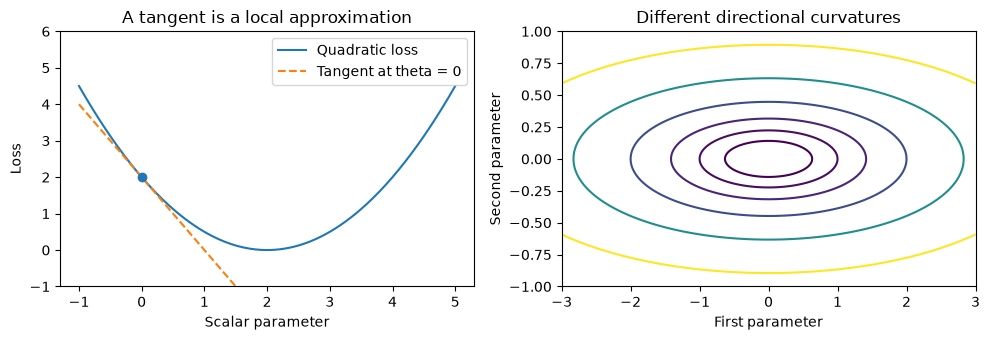

In [2]:
import numpy as np
import matplotlib.pyplot as plt

demo_theta = np.linspace(-1.0, 5.0, 300)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(demo_theta, 0.5 * (demo_theta - 2.0) ** 2, label="Quadratic loss")
axes[0].plot(demo_theta, 2.0 - 2.0 * demo_theta, "--", label="Tangent at theta = 0")
axes[0].scatter([0], [2], zorder=3)
axes[0].set(xlabel="Scalar parameter", ylabel="Loss", ylim=(-1, 6), title="A tangent is a local approximation")
axes[0].legend()
demo_u, demo_v = np.meshgrid(np.linspace(-3, 3, 160), np.linspace(-1, 1, 160))
axes[1].contour(demo_u, demo_v, 0.5 * (demo_u**2 + 20 * demo_v**2), levels=[0.2, 0.5, 1, 2, 4, 8])
axes[1].set(xlabel="First parameter", ylabel="Second parameter", title="Different directional curvatures")
fig.tight_layout()
plt.show()

The next demonstration samples from four **fixed gradient values**, not a training run. All estimates are formed at one imagined parameter state. Drawing four times with replacement can repeat an example, so its mean can still differ from the exact full-data gradient.

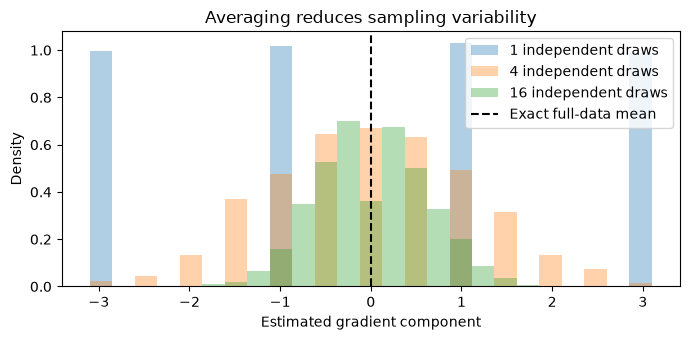

In [7]:
demo_rng = np.random.default_rng(202)
demo_gradients = np.array([-3.0, -1.0, 1.0, 3.0])
fig, ax = plt.subplots(figsize=(7, 3.5))
for demo_size in (1, 4, 16):
    demo_estimates = demo_rng.choice(demo_gradients, size=(2000, demo_size), replace=True).mean(axis=1)
    ax.hist(demo_estimates, bins=np.linspace(-3.1, 3.1, 26), density=True, alpha=0.35, label=f"{demo_size} independent draws")
ax.axvline(demo_gradients.mean(), color="black", linestyle="--", label="Exact full-data mean")
ax.set(xlabel="Estimated gradient component", ylabel="Density", title="Averaging reduces sampling variability")
ax.legend()
fig.tight_layout()
plt.show()

### An optimization path through parameter space

For the illustrative quadratic $J(u,v)=(u^2+8v^2)/2$, the gradient is
$(u,8v)$. With learning rate $\alpha=0.2$, one step multiplies $u$ by $0.8$
and $v$ by $-0.6$. Starting at $(2.5,0.9)$, the exact states after $k$ steps
are therefore $u_k=2.5(0.8)^k$ and $v_k=0.9(-0.6)^k$.

The left panel marks those states on loss contours; the sign changes in the
second coordinate produce a narrowing zigzag. The right panel evaluates the
full quadratic loss at each state. These are direct evaluations of an already
derived recurrence, with no general optimizer implementation. This smooth,
known-curvature example does not imply that arbitrary objectives decrease at
the same rate.

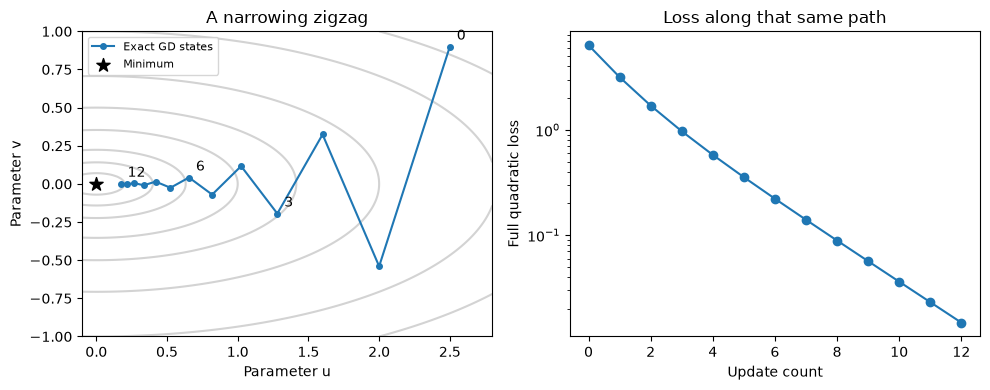

In [4]:
intuition_steps = np.arange(13)
intuition_trajectory = np.column_stack((
    2.5 * .8**intuition_steps, .9 * (-.6)**intuition_steps
))
intuition_trajectory_losses = (
    intuition_trajectory[:, 0]**2 + 8 * intuition_trajectory[:, 1]**2
) / 2
intuition_u, intuition_v = np.meshgrid(np.linspace(-.1, 2.8, 180), np.linspace(-1, 1, 150))
intuition_path_figure, intuition_path_axes = plt.subplots(1, 2, figsize=(10, 4))
intuition_path_axes[0].contour(
    intuition_u, intuition_v, (intuition_u**2 + 8 * intuition_v**2) / 2,
    levels=[.02, .08, .2, .5, 1, 2, 4, 6], colors="lightgray",
)
intuition_path_axes[0].plot(*intuition_trajectory.T, "o-", markersize=4, label="Exact GD states")
intuition_path_axes[0].scatter([0], [0], marker="*", s=100, color="black", label="Minimum")
for intuition_k in (0, 3, 6, 12):
    intuition_path_axes[0].annotate(
        str(intuition_k), intuition_trajectory[intuition_k],
        xytext=(5, 5), textcoords="offset points",
    )
intuition_path_axes[0].set(xlabel="Parameter u", ylabel="Parameter v", title="A narrowing zigzag")
intuition_path_axes[0].legend(fontsize=8)
intuition_path_axes[1].semilogy(intuition_steps, intuition_trajectory_losses, "o-")
intuition_path_axes[1].set(xlabel="Update count", ylabel="Full quadratic loss", title="Loss along that same path")
intuition_path_figure.tight_layout()
plt.show()

### Comparing update rules with the same observations

Use four individual losses $\ell_i(\theta)=(\theta-a_i)^2/2$ with
$a_i\in\{-2,-1,1,2\}$. Their mean is $J(\theta)=\theta^2/2+1.25$,
minimized at zero. A batch's mean gradient is $\theta-\bar a$, so an
update has the form $\theta'=r\theta+\alpha\bar a$, where
$r=1-\alpha$. Repeated substitution gives the exact state
$$
\theta_k=r^k\theta_0+
\alpha\sum_{j=0}^{k-1}r^{k-1-j}\bar a_j.
$$
For $k=0$ the sum is empty and equals zero. The code evaluates this formula
for predetermined batch-mean sequences; it does not define a reusable trainer.

All three methods start at $\theta_0=3$, use $\alpha=0.15$, and see the same
seeded observation order in each of 20 epochs. Batch sizes are four, one, and
two. Thus all process 80 observations, while making 20, 80, and 40 updates.
The first two panels display the same full-data excess loss,
$J(\theta)-J(0)=\theta^2/2$, against different work measures. The third shows
parameter fluctuations. Losses are recomputed at the displayed states, not
taken from changing mini-batches.

This controls the data, order, initial state, per-update rate, and data exposure.
It does not equalize update counts or establish the best learning rate for
each method. A constant-rate sampled method can fluctuate near the minimum;
one seed on this scalar toy problem is not a general ranking of optimizers.

Batch GD updates: 20 examples: 80 last full loss: 1.2567603556245115
SGD updates: 80 examples: 80 last full loss: 1.2560953110772033
Mini-batch SGD updates: 40 examples: 80 last full loss: 1.2502645855364845


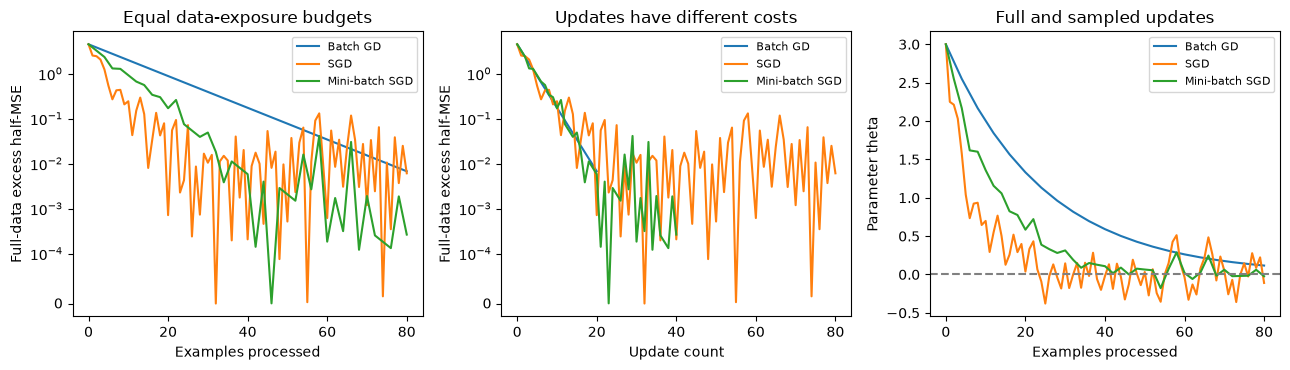

In [5]:
intuition_batch_rng = np.random.default_rng(308)
intuition_orders = np.array([
    intuition_batch_rng.permutation([-2., -1., 1., 2.]) for _ in range(20)
])
intuition_schedules = {
    "Batch GD": (intuition_orders.mean(axis=1), 4),
    "SGD": (intuition_orders.ravel(), 1),
    "Mini-batch SGD": (intuition_orders.reshape(-1, 2).mean(axis=1), 2),
}
intuition_alpha, intuition_initial = .15, 3.
intuition_r = 1 - intuition_alpha
intuition_comparison = {}
intuition_comparison_figure, intuition_comparison_axes = plt.subplots(1, 3, figsize=(13, 3.8))
for intuition_method, (intuition_means, intuition_size) in intuition_schedules.items():
    intuition_counts = np.arange(len(intuition_means) + 1)
    intuition_states = np.array([
        intuition_initial * intuition_r**k
        + intuition_alpha * np.dot(
            intuition_r**np.arange(k - 1, -1, -1), intuition_means[:k]
        )
        for k in intuition_counts
    ])
    intuition_excess_loss = intuition_states**2 / 2
    intuition_examples = intuition_counts * intuition_size
    intuition_comparison[intuition_method] = {
        "states": intuition_states, "excess_loss": intuition_excess_loss,
        "updates": intuition_counts, "examples": intuition_examples,
    }
    intuition_comparison_axes[0].plot(intuition_examples, intuition_excess_loss, label=intuition_method)
    intuition_comparison_axes[1].plot(intuition_counts, intuition_excess_loss, label=intuition_method)
    intuition_comparison_axes[2].plot(intuition_examples, intuition_states, label=intuition_method)
    print(intuition_method, "updates:", intuition_counts[-1],
          "examples:", intuition_examples[-1], "last full loss:", 1.25 + intuition_excess_loss[-1])
for intuition_ax in intuition_comparison_axes[:2]:
    intuition_ax.set_yscale("symlog", linthresh=1e-4)
    intuition_ax.set_ylabel("Full-data excess half-MSE")
    intuition_ax.legend(fontsize=8)
intuition_comparison_axes[0].set(xlabel="Examples processed", title="Equal data-exposure budgets")
intuition_comparison_axes[1].set(xlabel="Update count", title="Updates have different costs")
intuition_comparison_axes[2].axhline(0, color="gray", linestyle="--")
intuition_comparison_axes[2].set(xlabel="Examples processed", ylabel="Parameter theta", title="Full and sampled updates")
intuition_comparison_axes[2].legend(fontsize=8)
intuition_comparison_figure.tight_layout()
plt.show()

### Exercise 2.13 — Explore stability and oscillation

**Type:** Experimental · **Answer:** Code

Run your batch optimizer on quadratics with at least two curvatures and several rates spanning the derived boundary. Plot loss and parameter error against update count. Include rates exactly at and beyond the boundary.

**Expected outcome:** Plots with initial values, curvature, learning rates, and the distinction between shrinking oscillation and growing error clearly documented.

In [ ]:
# Your code for Exercise 2.13.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.13**

Choose rates through the product alpha times curvature, so different curvatures have comparable regimes.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.13**

This investigation uses `batch_descent` from Solution 2.09. With minimizer one and initial parameter three, the theoretical error is $2(1-\alpha c)^t$, making every plotted trajectory independently interpretable.

~~~python
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for curvature in [1., 4.]:
    for product in [0.2, 1.5, 2., 2.2]:
        rate = product / curvature
        objective = lambda t, c=curvature: (
            float(c * np.sum((t - 1)**2) / 2), c * (t - 1))
        run = batch_descent(objective, [3.], rate, 60)
        label = f"c={curvature:g}, alpha*c={product:g}"
        axes[0].plot(run["losses"], label=label)
        axes[1].plot(run["states"][:, 0] - 1, label=label)
        np.testing.assert_allclose(
            run["states"][:, 0] - 1,
            2 * (1-product)**np.arange(61), atol=1e-8, rtol=1e-8)
axes[0].set(yscale="log", xlabel="Updates", ylabel="Loss")
axes[1].set(xlabel="Updates", ylabel="Signed parameter error")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()
~~~

Products $0.2$ and $1.5$ shrink errors; $1.5$ alternates sign. Product two preserves nonzero error magnitude, and $2.2$ grows it. The signed-error plot can be dominated by the unstable run, so inspect stable curves separately when interpreting fine detail.

</details>

The following data have very different feature scales. The deterministic target rule is used only to create a study dataset. Independent Gaussian noise prevents an exact fit; no fitting routine is provided.

In [9]:
demo_data_rng = np.random.default_rng(203)
demo_X = demo_data_rng.normal(size=(90, 2)) * np.array([1.0, 1000.0])
demo_y = 1.0 + 2.0 * demo_X[:, 0] - 0.003 * demo_X[:, 1] + demo_data_rng.normal(0.0, 0.2, 90)
demo_order = demo_data_rng.permutation(90)
demo_train_ids, demo_validation_ids = demo_order[:65], demo_order[65:]
print("Training and validation sizes:", len(demo_train_ids), len(demo_validation_ids))
print("Training feature standard deviations:", demo_X[demo_train_ids].std(axis=0))

Training and validation sizes: 65 25
Training feature standard deviations: [9.14183930e-01 9.63434348e+02]


### Exercise 2.14 — Compare work and feature scales

**Type:** Experimental · **Answer:** Code

Use the supplied split with your regression implementation. Compare batch, stochastic, and mini-batch training on raw and training-standardized features. Tune rates using training/validation behavior, record at least three seeds for stochastic order, and plot full training loss against examples processed as well as against updates.

**Expected outcome:** A documented, reproducible comparison with equal data-pass budgets. Report instability when it occurs and keep scaling statistics fixed across validation evaluations.

In [ ]:
# Your code for Exercise 2.14.
# TODO: implement the task above and record the requested checks or plots.

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.14**

Compare equal data passes, use actual full losses, and select rates without choosing the luckiest seed.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.14**

Run the supplied dataset demonstration first. This uses Solutions 2.10–2.12. Rates are selected by mean validation half-MSE over three order seeds, separately for each scale treatment and batch size. All runs process 25 training passes.

~~~python
ref_train_X, ref_train_y = demo_X[demo_train_ids], demo_y[demo_train_ids]
ref_valid_X, ref_valid_y = demo_X[demo_validation_ids], demo_y[demo_validation_ids]
ref_mean, ref_scale = fit_standardizer(ref_train_X)
ref_selected = []
for treatment in ["raw", "standardized"]:
    train_X = (ref_train_X if treatment == "raw"
               else standardize(ref_train_X, ref_mean, ref_scale))
    valid_X = (ref_valid_X if treatment == "raw"
               else standardize(ref_valid_X, ref_mean, ref_scale))
    rates = [1e-8, 1e-7] if treatment == "raw" else [0.01, 0.05]
    for size in [len(train_X), 1, 8]:
        candidates = []
        for rate in rates:
            runs, scores = [], []
            for seed in [0, 1, 2]:
                run = gd_regression(train_X, ref_train_y, epochs=25,
                                    learning_rate=rate, batch_size=size, seed=seed)
                theta = run["theta"]
                score = np.mean(
                    (theta[0] + valid_X @ theta[1:] - ref_valid_y)**2) / 2
                runs.append(run)
                scores.append(score)
            candidates.append((np.mean(scores), rate, runs, np.std(scores)))
        score, rate, runs, spread = min(candidates, key=lambda item: item[0])
        ref_selected.append((treatment, size, rate, runs[0]))
        print(treatment, "batch", size, "rate", rate,
              "validation half-MSE mean/std", score, spread)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for treatment, size, rate, run in ref_selected:
    history = run["history"]
    label = f"{treatment}, batch={size}"
    axes[0].plot(history[:, 2], history[:, 3], label=label)
    axes[1].plot(history[:, 1], history[:, 3], label=label)
axes[0].set(xlabel="Examples processed", ylabel="Full training half-MSE")
axes[1].set(xlabel="Updates", ylabel="Full training half-MSE")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()
~~~

Raw features require much smaller stable rates because their curvature is large. Standardization can make progress in different parameter directions more balanced; this is a finite-budget comparison, not proof that scaling always wins. Report rate candidates and seed variability as part of the result. Validation is used for selection, so its selected score is not an untouched final test estimate.

</details>

## 7. Interpretation and critical analysis

A noisy loss curve is not automatically incorrect, and a smooth curve is not automatically evidence of good generalization. Small batches can produce many cheap but noisy updates; large batches can use vectorized arithmetic efficiently while making fewer updates per pass. Wall-clock time, examples processed, and update count answer different questions. Report which resource is controlled.

With a constant stochastic learning rate, noise can keep parameters fluctuating near a minimum. Decreasing the rate can reduce this effect at the cost of slower movement. Data order, conditioning, and the chosen loss convention also matter. Rescaling an objective from half-MSE to MSE doubles its gradient, so copying an unchanged rate doubles each gradient-based step.

### Exercise 2.15 — Challenge an unfair optimizer comparison

**Type:** Critical · **Answer:** Markdown

A report claims mini-batches are superior because they have lower loss after 100 updates than full-batch training. Identify missing information that could reverse the conclusion. Design a comparison protocol and state which result would still be specific to the chosen dataset.

**Expected outcome:** A critique covering computational work, learning-rate selection, randomness, and held-out evaluation.

**Your response to Exercise 2.15**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.15**

Equal update counts can hide very different numbers of processed examples.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.15**

One full-batch update costs gradients from all $n$ observations, whereas a mini-batch update uses only its batch. After 100 updates, data passes and work therefore differ. The report also omits learning rates, initial states, sampling, seed variability, and tuning effort.

A useful protocol fixes a dataset split and initial state, chooses rate candidates using validation data, compares equal examples-processed budgets, and also reports updates and measured wall time. Repeat stochastic orders with several seeds. The ranking remains conditional on the dataset, implementation, hardware, loss, and selected hyperparameters.

</details>

## 8. Review questions and knowledge checks

### Exercise 2.16 — Describe a complete update

**Type:** Conceptual · **Answer:** Markdown

Describe where a batch gradient is evaluated, how a mini-batch estimate is averaged, when parameters change, and when full training loss is measured. Explain why averaging gradients computed before any updates is different from averaging parameters after sequential updates.

**Expected outcome:** A precise sequence in your own words that would prevent accidental mixing of parameter states.

**Your response to Exercise 2.16**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.16**

Label the parameter snapshot associated with each gradient and each reported loss.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.16**

At update $t$, hold $\theta^{(t)}$ fixed while evaluating every selected example's gradient. Average by the actual batch size and form all parameter changes from that vector. Then apply the update. Reevaluate full loss at a declared checkpoint using one resulting parameter state.

Gradients accumulated at the same original state can be averaged into a full-batch gradient. Sequential updates change later evaluation points. Averaging final parameters from those trajectories generally gives neither the original-state batch update nor the sequential endpoint, so it describes a different procedure.

</details>

### Exercise 2.17 — Connect feature scaling to parameters

**Type:** Mathematical · **Answer:** Markdown

Starting from standardized predictions $b'+\sum_jw'_j(x_j-\mu_j)/s_j$, derive weights and intercept in the original units. Explain the assumptions under which this conversion is valid.

**Expected outcome:** An expansion and coefficient comparison, including a treatment of zero-scale features.

**Your response to Exercise 2.17**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

<details>
<summary>Show hint</summary>

**Hint — Exercise 2.17**

Expand the standardized prediction and collect coefficients of each original input.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 2.17**

Expanding gives
$$
b'+\sum_j\frac{w'_j}{s_j}x_j-\sum_j\frac{w'_j\mu_j}{s_j}.
$$
Thus $w_j=w'_j/s_j$ and $b=b'-\sum_jw'_j\mu_j/s_j$.

The transformation must use the same stored means and positive scales as fitting; coefficients and intercept must refer to the same feature ordering. A true zero standard deviation cannot be divided by. With the reference scale-one policy, use that stored scale consistently, while recognizing that a constant training feature has no independently learned effect.

</details>

## 9. Summary and next learning steps

Gradient descent follows local slope information, with curvature controlling whether a finite step is useful. Batch, stochastic, and mini-batch methods differ in the gradient information and work used per update. Unbiased gradient estimates require a sampling statement; they do not imply monotone sampled trajectories. Scaling, averaging, randomness, and monitoring are parts of an experiment's definition.

Before moving on, verify one update by hand, check that a final short batch is retained, and compare full losses at consistent parameter states. You now have the optimization tools needed for [Logistic Regression](logistic-regression.ipynb), where the output becomes a probability and the objective comes from a probabilistic model.